In [1]:
!pip install -U datasets transformers evaluate accelerate tdqm gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 1.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 MB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.9/323.9 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 112.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
 

### MNLI Dataset and Natural Language Inference

The Multi-Genre Natural Language Inference Corpus is a crowdsourced collection of sentence pairs with textual entailment annotations. Given a premise sentence and a hypothesis sentence, the task is to predict whether the premise entails the hypothesis (entailment), contradicts the hypothesis (contradiction), or neither (neutral). The premise sentences are gathered from ten different sources, including transcribed speech, fiction, and government reports. The authors of the benchmark use the standard test set, for which they obtained private labels from the RTE authors, and evaluate on both the matched (in-domain) and mismatched (cross-domain) section. They also uses and recommend the SNLI corpus as 550k examples of auxiliary training data.


For each instance, there is a string for the `premise`, a string for the `hypothesis`, and an integer for the `label`. Note that each premise may appear three times with a different hypothesis and label.

```
Sample Instance:
{'premise': 'Two women are embracing while holding to go packages.'
 'hypothesis': 'The sisters are hugging goodbye while holding to go packages after just eating lunch.'
 'label': 1}
 ```

- premise: a string used to determine the truthfulness of the hypothesis
- hypothesis: a string that may be true, false, or whose truth conditions may not be knowable when compared to the premise
- label: an integer whose value may be either `0`, indicating that the hypothesis `entails` the premise, `1`, indicating that the premise and hypothesis `neither entail nor contradict `each other, or `2`, indicating that the hypothesis `contradicts` the premise. Dataset instances which don't have any gold label are marked with -1 label. Make sure you filter them before starting the training using datasets.Dataset.filter

**mnli_matched**

The matched validation and test splits from MNLI.

**mnli_mismatched**

The mismatched validation and test splits from MNLI.


Task here is Natural Language Inference (NLI), also known as Recognizing Textual Entailment (RTE), is the task of determining the inference relation between two (short, ordered) texts: entailment, contradiction, or neutral.

### Knowledge Distillation

**Knowledge distillation** is a technique where a smaller task-specific model (the **student**) learns to mimic the behavior of a larger, more accurate model (the **teacher**). Instead of just training on the ground-truth labels, the student also tries to match the **soft predictions** (logits) from the teacher.

**Goal**: Transfer knowledge from a large model to a small one for faster, cheaper inference.

For better language representation and faster inference, we can use distillation for pretraining as well and then also be finetuned with good performances on wide range of tasks.

### Task-Specific Models

A **task-specific model** is trained for one particular NLP task, like:

* Sentiment analysis
* Named Entity Recognition (NER)
* Question answering
* Text classification

These models are **fine-tuned** versions of base language models to specialize in one task.

### DistillBert

DistillBERT authors trained smaller version of BERT from bigger BERT using knowledge distillation. Note that authors distilled the smaller model pretraining(for better language representation) and not as task specific.

DistilBERT is pretrained by knowledge distillation to create a smaller model with faster inference and requires less compute to train. DistilBERT demonstrated similar performance to a larger transformer language model.
In other words, DistilBERT is a **smaller, faster version of BERT**, trained via knowledge distillation.

1. Start with **BERT-base** as the **teacher**.
2. Train a smaller student model (half the layers).
3. Optimize the student to:
   * Match the **teacher's logits**
   * Match the **teacher’s hidden states**
   * Predict the correct labels through a `triple loss objective` during pretraining
    - language modeling loss
    - distillation loss
    - cosine-distance loss
4. Result: **60% smaller**, **97% performance**, and **2x faster** than BERT.


Paper: https://arxiv.org/pdf/1910.01108

---

### How DistilBERT Differs from Standard KD

While **standard knowledge distillation** typically uses **only logits** from the teacher to guide the student, **DistilBERT** uses a **multi-objective loss** to transfer deeper knowledge.

---

### Standard KD Loss:

Usually:

```python
Loss = α * CrossEntropy(student_logits, true_labels) + β * KL(student_logits || teacher_logits)
```

Focus is mostly on output probabilities (soft labels).

---

### DistilBERT's Multi-Objective Loss:

DistilBERT adds **intermediate supervision** from BERT:

1. **Kullback-Leibler (KL) loss** on logits (as in standard KD)
2. **Cosine embedding loss** between hidden states (student vs. teacher)
3. **Cross-entropy loss** with true labels

So the total loss becomes:

```python
Loss = λ1 * KD_loss (logits)
     + λ2 * Cosine_loss (hidden states)
     + λ3 * CE_loss (true labels)
```

This richer signal helps the student better **capture BERT’s internal representations**, not just its outputs.

---


| Aspect                   | Standard KD    | DistilBERT                            |
| ------------------------ | -------------- | ------------------------------------- |
| Output supervision       | ✅ Yes (logits) | ✅ Yes (logits)                        |
| Hidden state supervision | ❌ No           | ✅ Yes (cosine loss on hidden layers)  |
| True label loss          | Optional       | ✅ Always used (cross-entropy)         |
| Layer alignment          | Optional       | ✅ Student aligns every 2nd BERT layer |

---

This hybrid distillation approach makes **DistilBERT more task-agnostic and general-purpose**, while many KD models are trained for **specific tasks only**.



In [ ]:
import datasets
from datasets import load_dataset
import transformers

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from huggingface_hub import HfApi, create_repo, upload_folder, get_full_repo_name
from google.colab import userdata
import os

import random, math, time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

### Load Dataset

In [ ]:
from datasets import load_dataset

ds = load_dataset("glue", "mnli")

ds

README.md: 0.00B [00:00, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/52.2M [00:00<?, ?B/s]

(…)alidation_matched-00000-of-00001.parquet:   0%|          | 0.00/1.21M [00:00<?, ?B/s]

(…)dation_mismatched-00000-of-00001.parquet:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

test_matched-00000-of-00001.parquet:   0%|          | 0.00/1.22M [00:00<?, ?B/s]

test_mismatched-00000-of-00001.parquet:   0%|          | 0.00/1.26M [00:00<?, ?B/s]

... (2 outputs left out)

Generating validation_mismatched split:   0%|          | 0/9832 [00:00<?, ? examples/s]

Generating test_matched split:   0%|          | 0/9796 [00:00<?, ? examples/s]

Generating test_mismatched split:   0%|          | 0/9847 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9847
    })
})

In [ ]:
ds["train"].features

{'premise': Value(dtype='string', id=None),
 'hypothesis': Value(dtype='string', id=None),
 'label': ClassLabel(names=['entailment', 'neutral', 'contradiction'], id=None),
 'idx': Value(dtype='int32', id=None)}

In [ ]:
# Labels
ds["train"].features["label"].names

['entailment', 'neutral', 'contradiction']

In [ ]:
labels = ds["train"].features["label"].names
label2id = {label: idx for idx, label in enumerate(labels)}
id2label = {v: k for k, v in label2id.items()}

labels, label2id, id2label

(['entailment', 'neutral', 'contradiction'],
 {'entailment': 0, 'neutral': 1, 'contradiction': 2},
 {0: 'entailment', 1: 'neutral', 2: 'contradiction'})

### Preprocessing

In [ ]:
from transformers import AutoTokenizer

teacher_model_id = "bert-base-uncased"  # same teacher tokenizer
tokenizer = AutoTokenizer.from_pretrained(teacher_model_id)

tokenizer

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizerFast(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}
)

In [ ]:
ds["train"][0]["premise"], ds["train"][0]["hypothesis"]

('Conceptually cream skimming has two basic dimensions - product and geography.',
 'Product and geography are what make cream skimming work. ')

In [ ]:
args = (ds["train"][0]["premise"], ds["train"][0]["hypothesis"])
inputs = tokenizer(*args, max_length=128, truncation=True)
inputs

{'input_ids': [101, 17158, 2135, 6949, 8301, 25057, 2038, 2048, 3937, 9646, 1011, 4031, 1998, 10505, 1012, 102, 4031, 1998, 10505, 2024, 2054, 2191, 6949, 8301, 25057, 2147, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [ ]:
len(inputs["input_ids"])

28

In [ ]:
tokenizer.convert_ids_to_tokens(inputs["input_ids"])

['[CLS]',
 'conceptual',
 '##ly',
 'cream',
 'ski',
 '##mming',
 'has',
 'two',
 'basic',
 'dimensions',
 '-',
 'product',
 'and',
 'geography',
 '.',
 '[SEP]',
 'product',
 'and',
 'geography',
 'are',
 'what',
 'make',
 'cream',
 'ski',
 '##mming',
 'work',
 '.',
 '[SEP]']

In [ ]:
tokenizer.decode(inputs["input_ids"])

'[CLS] conceptually cream skimming has two basic dimensions - product and geography. [SEP] product and geography are what make cream skimming work. [SEP]'

In [ ]:
max_input_seq_length = 128

def tokenize_fn(examples):
    args = (examples["premise"], examples["hypothesis"])
    inputs = tokenizer(*args, max_length=max_input_seq_length, truncation=True)
    return inputs

tokenized_ds = ds.map(tokenize_fn, batched=True)
tokenized_ds

Map:   0%|          | 0/392702 [00:00<?, ? examples/s]

Map:   0%|          | 0/9815 [00:00<?, ? examples/s]

Map:   0%|          | 0/9832 [00:00<?, ? examples/s]

Map:   0%|          | 0/9796 [00:00<?, ? examples/s]

Map:   0%|          | 0/9847 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9847
    })
})

In [ ]:
tokenized_ds = tokenized_ds.remove_columns(["premise", "hypothesis", "idx"])
tokenized_ds = tokenized_ds.rename_column("label", "labels")
tokenized_ds.set_format("torch")
tokenized_ds

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9847
    })
})

### Teacher Model

In [ ]:
from transformers import AutoModelForSequenceClassification

teacher_model_id = "bert-base-uncased"

num_labels = len(ds["train"].unique("label"))  # 3

teacher_model = AutoModelForSequenceClassification.from_pretrained(
    teacher_model_id, num_labels=num_labels, id2label=id2label, label2id=label2id
)

teacher_model

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

### DataLoaders

In [ ]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

collator = DataCollatorWithPadding(tokenizer)

train_ds = tokenized_ds["train"].shuffle(seed=1234).select(range(100000))
val_ds = tokenized_ds["validation_mismatched"].shuffle(seed=1234).select(range(1000))
test_ds = tokenized_ds["test_mismatched"].shuffle(seed=1234).select(range(1000))

train_dl = DataLoader(train_ds, shuffle=True, batch_size=32, collate_fn=collator)
eval_dl = DataLoader(val_ds, batch_size=32, collate_fn=collator)
test_dl = DataLoader(test_ds, batch_size=32, collate_fn=collator)

In [ ]:
for batch in train_dl:
    break

batch

{'labels': tensor([1, 1, 1, 1, 2, 0, 0, 0, 1, 1, 2, 1, 2, 2, 0, 0, 1, 1, 2, 0, 0, 1, 0, 0,
        2, 0, 1, 2, 2, 1, 0, 1]), 'input_ids': tensor([[  101,  2115,  2115,  ...,  2564,  1012,   102],
        [  101,  2000,  9462,  ...,     0,     0,     0],
        [  101,  2748,  2092,  ...,     0,     0,     0],
        ...,
        [  101, 11332,  4811,  ...,     0,     0,     0],
        [  101,  1996,  4193,  ...,     0,     0,     0],
        [  101,  2107, 23617,  ...,     0,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]])}

In [ ]:
batch["labels"].shape, batch["input_ids"].shape, batch["token_type_ids"].shape, batch["attention_mask"].shape

(torch.Size([32]),
 torch.Size([32, 77]),
 torch.Size([32, 77]),
 torch.Size([32, 77]))

### Design the Model

**Student architecture from paper:**

In paper, the student- DistilBERT- has the same general architecture as BERT.

- The `token-type embeddings` and the `pooler` are removed while the `number of layers is reduced by a factor of 2`.

Most of the operations used in the Transformer architecture (linear layer and layer normalization) are highly optimized in modern linear algebra frameworks and our investigations showed that variations on the last dimension of the tensor (hidden size dimension) have a smaller impact on computation efficiency (for a fixed parameters budget) than variations on other factors like the number of layers. Thus we focus on reducing the number of layers.

**Student initialization**

In addition to the previously described optimization and architectural choices, an important element in our training procedure is to find the right initialization for the sub-network to converge. Taking advantage of the common dimensionality between teacher and student networks, we initialize the student from the teacher by taking one layer out of two starting with layer 0. The head of the model is also copied from teacher.

In [ ]:
teacher_model.config

BertConfig {
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "entailment",
    "1": "neutral",
    "2": "contradiction"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "label2id": {
    "contradiction": 2,
    "entailment": 0,
    "neutral": 1
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "torch_dtype": "float32",
  "transformers_version": "4.53.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

In [ ]:
configuration = teacher_model.config.to_dict()
configuration

{'return_dict': True,
 'output_hidden_states': False,
 'torchscript': False,
 'torch_dtype': 'float32',
 'use_bfloat16': False,
 'tf_legacy_loss': False,
 'pruned_heads': {},
 'tie_word_embeddings': True,
 'chunk_size_feed_forward': 0,
 'is_encoder_decoder': False,
 'is_decoder': False,
 'cross_attention_hidden_size': None,
 'add_cross_attention': False,
 'tie_encoder_decoder': False,
 'max_length': 20,
 'min_length': 0,
 'do_sample': False,
 'early_stopping': False,
 'num_beams': 1,
 'num_beam_groups': 1,
 'diversity_penalty': 0.0,
 'temperature': 1.0,
 'top_k': 50,
 'top_p': 1.0,
 'typical_p': 1.0,
 'repetition_penalty': 1.0,
 'length_penalty': 1.0,
 'no_repeat_ngram_size': 0,
 'encoder_no_repeat_ngram_size': 0,
 'bad_words_ids': None,
 'num_return_sequences': 1,
 'output_scores': False,
 'return_dict_in_generate': False,
 'forced_bos_token_id': None,
 'forced_eos_token_id': None,
 'remove_invalid_values': False,
 'exponential_decay_length_penalty': None,
 'suppress_tokens': None,
 '

In [ ]:
# Student Model
from transformers.models.bert.modeling_bert import BertPreTrainedModel, BertConfig

BertConfig

transformers.models.bert.configuration_bert.BertConfig

In [ ]:
# Student Model
from transformers.models.bert.modeling_bert import BertPreTrainedModel, BertConfig

# Half the layers
configuration["num_hidden_layers"] //= 2

# Load the config
configuration = BertConfig.from_dict(config_dict=configuration)

# Create uninitialized student model
model = type(teacher_model)(configuration)
model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-5): 6 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-1

In [ ]:
for name, _ in model.named_modules():
    print(name)


bert
bert.embeddings
bert.embeddings.word_embeddings
bert.embeddings.position_embeddings
bert.embeddings.token_type_embeddings
bert.embeddings.LayerNorm
bert.embeddings.dropout
bert.encoder
bert.encoder.layer
bert.encoder.layer.0
bert.encoder.layer.0.attention
bert.encoder.layer.0.attention.self
bert.encoder.layer.0.attention.self.query
bert.encoder.layer.0.attention.self.key
bert.encoder.layer.0.attention.self.value
bert.encoder.layer.0.attention.self.dropout
bert.encoder.layer.0.attention.output
bert.encoder.layer.0.attention.output.dense
bert.encoder.layer.0.attention.output.LayerNorm
bert.encoder.layer.0.attention.output.dropout
bert.encoder.layer.0.intermediate
bert.encoder.layer.0.intermediate.dense
bert.encoder.layer.0.intermediate.intermediate_act_fn
bert.encoder.layer.0.output
bert.encoder.layer.0.output.dense
bert.encoder.layer.0.output.LayerNorm
bert.encoder.layer.0.output.dropout
bert.encoder.layer.1
bert.encoder.layer.1.attention
bert.encoder.layer.1.attention.self
bert.e

In [ ]:
for name, _ in model.named_children():
    print(name)

bert
dropout
classifier


In [ ]:
for n, m in model.named_modules():
    print(f"{n}")
    for name, _ in m.named_children():
        print(f"\t>>>{name}")


	>>>bert
	>>>dropout
	>>>classifier
bert
	>>>embeddings
	>>>encoder
	>>>pooler
bert.embeddings
	>>>word_embeddings
	>>>position_embeddings
	>>>token_type_embeddings
	>>>LayerNorm
	>>>dropout
bert.embeddings.word_embeddings
bert.embeddings.position_embeddings
bert.embeddings.token_type_embeddings
bert.embeddings.LayerNorm
bert.embeddings.dropout
bert.encoder
	>>>layer
bert.encoder.layer
	>>>0
	>>>1
	>>>2
	>>>3
	>>>4
	>>>5
bert.encoder.layer.0
	>>>attention
	>>>intermediate
	>>>output
bert.encoder.layer.0.attention
	>>>self
	>>>output
bert.encoder.layer.0.attention.self
	>>>query
	>>>key
	>>>value
	>>>dropout
bert.encoder.layer.0.attention.self.query
bert.encoder.layer.0.attention.self.key
bert.encoder.layer.0.attention.self.value
bert.encoder.layer.0.attention.self.dropout
bert.encoder.layer.0.attention.output
	>>>dense
	>>>LayerNorm
	>>>dropout
bert.encoder.layer.0.attention.output.dense
bert.encoder.layer.0.attention.output.LayerNorm
bert.encoder.layer.0.attention.output.dropout
bert

In [ ]:
from transformers.models.bert.modeling_bert import BertModel

type(teacher_model), type(teacher_model).__name__, isinstance(teacher_model, BertModel)

(transformers.models.bert.modeling_bert.BertForSequenceClassification,
 'BertForSequenceClassification',
 False)

In [ ]:
from transformers.models.bert.modeling_bert import BertModel, BertEncoder

for name, module in teacher_model.named_modules():
    if isinstance(module, BertEncoder):
        for layer in next(module.children()):
            # print(type(layer)) # <class 'transformers.models.bert.modeling_bert.BertLayer'>
            print(type(layer).__name__)

BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer
BertLayer


In [ ]:
# Copy the weights from teacher to student
from transformers.models.bert.modeling_bert import BertModel, BertEncoder

def copy_weights(teacher_model, student_model):
    """
    Recursively copies the weights of the teacher to the student.
    This function is meant to be first called on a BertFor... model, but is then called on every children of that model recursively.
    The only part that's not fully copied is the encoder, of which only half is copied.
    """
    if isinstance(teacher_model, BertModel) or type(teacher_model).__name__.startswith("BertFor"):
        for teacher_child, student_child in zip(teacher_model.children(), student_model.children()):
            copy_weights(teacher_child, student_child) # recursion
    elif isinstance(teacher_model, BertEncoder):
        teacher_encoder_layers = [layer for layer in next(teacher_model.children())] # 12 layers
        student_encoder_layers = [layer for layer in next(student_model.children())] # 6 layers
        for i in range(len(student_encoder_layers)):
            student_encoder_layers[i].load_state_dict(teacher_encoder_layers[2+i].state_dict())
    else:
        student_model.load_state_dict(teacher_model.state_dict())

    return student_model

In [ ]:
model = copy_weights(teacher_model, model)

In [ ]:
def count_params(model):
    count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{ count / (1000 ** 2):.1f} M params")
    return count

count_params(teacher_model)
count_params(model)

109.5 M params
67.0 M params


66957315

In [ ]:
(count_params(model) / count_params(teacher_model)) * 100  # 40% less params

67.0 M params
109.5 M params


61.15686353435797

### Distill Bert Loss

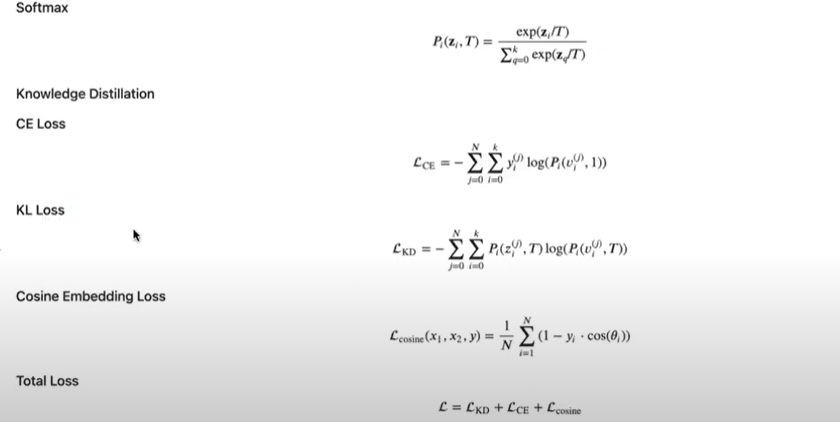

In [ ]:
import torch.nn.functional as F

class DistillKLLoss(nn.Module):
    def __init__(self, device=None):
        super().__init__()
        self.device = device

    def forward(self, teacher_logits, student_logits, temperature=1):
        T = temperature #.cuda()
        KD_loss = nn.KLDivLoss(reduction="batchmean")(F.log_softmax(student_logits / T, dim=-1), F.softmax(teacher_logits / T, dim=-1)) * T * T
        return KD_loss

criterion_divergence = DistillKLLoss(device=device)
criterion_cosine = nn.CosineEmbeddingLoss()

This is core to the distillation process, where:

- The student learns to mimic the teacher's soft probabilities (after temperature scaling).

- The loss encourages the student’s output distribution to be close to the teacher’s.

- The * T * T term rescales the gradients, as per Hinton et al.’s original distillation paper.

Cosine embedding loss measures the similarity or dissimilarity between two input vectors by computing the cosine similarity between them and penalizing the difference based on a label. It is commonly used in tasks where learning embeddings that capture semantic relationships (similarity/dissimilarity) between data points is crucial.

### Optimizer

In [ ]:
from torch.optim import Adam

optimizer = Adam(model.parameters(), lr=5e-5)

### Scheduler

In [ ]:
from transformers import get_scheduler

num_epochs = 5
num_steps_per_epoch = len(train_dl)
num_training_steps = num_steps_per_epoch * num_epochs

scheduler = get_scheduler("linear", optimizer=optimizer, num_training_steps=num_training_steps, num_warmup_steps=0)

### Metric

In [ ]:
import evaluate

metric = evaluate.load("glue", "mnli")
metric

EvaluationModule(name: "glue", module_type: "metric", features: {'predictions': Value(dtype='int64', id=None), 'references': Value(dtype='int64', id=None)}, usage: """
Compute GLUE evaluation metric associated to each GLUE dataset.
Args:
    predictions: list of predictions to score.
        Each translation should be tokenized into a list of tokens.
    references: list of lists of references for each translation.
        Each reference should be tokenized into a list of tokens.
Returns: depending on the GLUE subset, one or several of:
    "accuracy": Accuracy
    "f1": F1 score
    "pearson": Pearson Correlation
    "spearmanr": Spearman Correlation
    "matthews_correlation": Matthew Correlation
Examples:

    >>> glue_metric = evaluate.load('glue', 'sst2')  # 'sst2' or any of ["mnli", "mnli_mismatched", "mnli_matched", "qnli", "rte", "wnli", "hans"]
    >>> references = [0, 1]
    >>> predictions = [0, 1]
    >>> results = glue_metric.compute(predictions=predictions, references=ref

### Training

In [ ]:
from tqdm.auto import  tqdm

progress_bar = tqdm(range(num_training_steps))

model = model.to(device)
teacher_model = teacher_model.to(device)

train_losses = []
train_losses_cls = []
train_losses_div = []
train_losses_cos = []
eval_losses = []
eval_metrics = 0

for epoch in range(num_epochs):
    model.train()
    teacher_model.eval()
    train_loss = 0
    train_loss_cls = 0
    train_loss_div = 0
    train_loss_cos = 0
    for step, batch in enumerate(train_dl):
        batch = {k: v.to(device) for k, v in batch.items()}
        # Student logits
        outputs = model(**batch)
        # Teacher logits
        with torch.no_grad():
            outputs_teacher = teacher_model(**batch)
        assert outputs.logits.size() == outputs_teacher.logits.size()
        # Classification Loss
        loss_cls = outputs.loss
        # Distillation Loss
        loss_div = criterion_divergence(outputs.logits, outputs_teacher.logits)
        # Cosine Loss
        loss_cos = criterion_cosine(outputs_teacher.logits, outputs.logits, torch.ones(outputs_teacher.logits.size()[0]).to(device))
        # Average Loss
        loss = (loss_cls + loss_div + loss_cos ) / 3
        # Accumulate losses
        train_loss += loss.item()
        train_loss_cls += loss_cls.item()
        train_loss_div += loss_div.item()
        train_loss_cos += loss_cos.item()

        loss.backward()
        optimizer.step()  # update params here after accumulating for gradient_accumulation_steps
        scheduler.step()
        optimizer.zero_grad()
        progress_bar.update(1)
    train_losses.append(train_loss / len(train_dl))
    train_losses_cls.append(train_loss_cls / len(train_dl))
    train_losses_div.append(train_loss_div / len(train_dl))
    train_losses_cos.append(train_loss_cos / len(train_dl))
    print(f"Epoch: {epoch+1} | Train Loss: {train_loss / len(train_dl):.4f}")
    print(f"\t - Classification Loss: {train_loss_cls / len(train_dl):.4f}")
    print(f"\t - Distillation Loss: {train_losses_div / len(train_dl):.4f}")
    print(f"\t - Cosine Loss: {train_losses_cos / len(train_dl):.4f}")

    model.eval()
    eval_loss = 0
    for step, batch in enumerate(eval_dl):
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.no_grad():
            outputs = model(**batch)
        loss_cls = outputs.loss
        preds = outputs.logits.argmax(dim=-1)
        eval_loss += loss_cls.item()
        metric.add_batch(predictions=preds, references=batch["labels"])
    results = metric.compute()
    eval_metrics += results["accuracy"]
    eval_losses.append(eval_loss / len(eval_dl))
    print(f"Epoch at {epoch+1}: Test Accuracy: {results['accuracy']:.4f}")

print("Average Metric", eval_metrics / num_epochs)

  0%|          | 0/15625 [00:00<?, ?it/s]

KeyboardInterrupt: 

ValueError: x and y must have same first dimension, but have shapes (5,) and (0,)

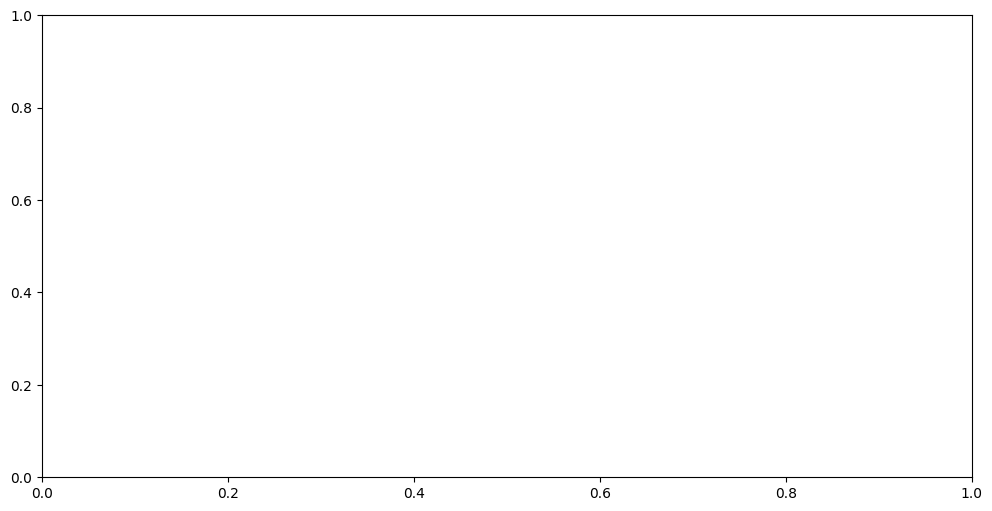

In [ ]:
import matplotlib.pyplot as plt

epochs_list = range(1, num_epochs + 1)

plt.figure(figsize=(12, 6))
plt.plot(epochs_list, train_losses, label="Total Train Loss")
plt.plot(epochs_list, train_losses_cls, label="Total Train Classification Loss")
plt.plot(epochs_list, train_losses_div, label="Total Train Loss Distillation")
plt.plot(epochs_list, train_losses_cos, label="Total Train Loss Cosine")
plt.plot(epochs_list, eval_losses, label="Validation Loss")

plt.title("Training and Validation Losses")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Final Version

Map:   0%|          | 0/392702 [00:00<?, ? examples/s]

Map:   0%|          | 0/9815 [00:00<?, ? examples/s]

Map:   0%|          | 0/9832 [00:00<?, ? examples/s]

Map:   0%|          | 0/9796 [00:00<?, ? examples/s]

Map:   0%|          | 0/9847 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total params reduced: 61.1569


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch: 1 | Train Loss: 1.1249
	 - Classification Loss: 0.4408
	 - Distillation Loss: 0.0200
	 - Cosine Loss: 0.1775
Epoch at 1: Test Accuracy: 0.3400
Epoch: 2 | Train Loss: 1.0904
	 - Classification Loss: 0.3829
	 - Distillation Loss: 0.0083
	 - Cosine Loss: 0.0502
Epoch at 2: Test Accuracy: 0.3600
Epoch: 3 | Train Loss: 1.1125
	 - Classification Loss: 0.3897
	 - Distillation Loss: 0.0088
	 - Cosine Loss: 0.0477
Epoch at 3: Test Accuracy: 0.3600
Average Metric 0.35333333333333333


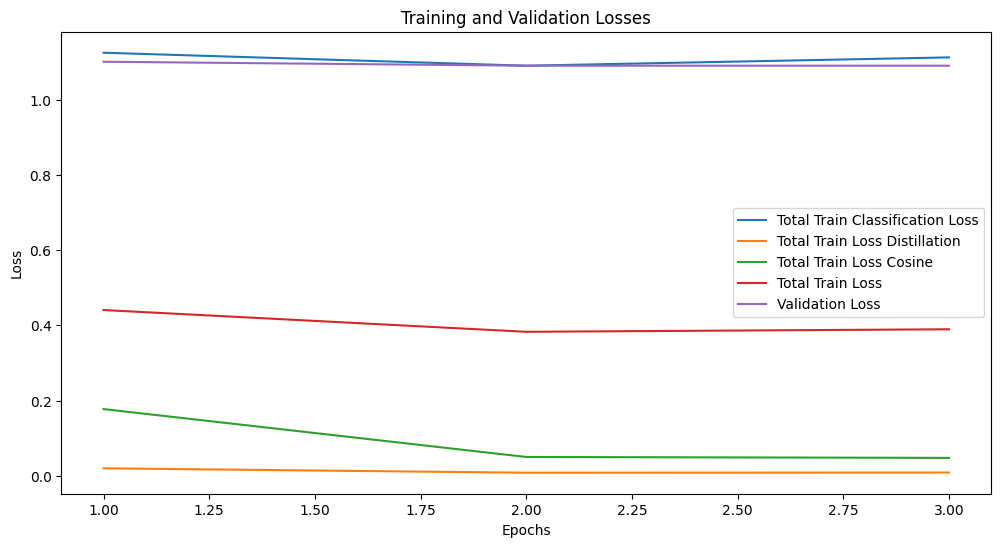

In [6]:
import datasets
from datasets import load_dataset

from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_scheduler

from transformers.models.bert.modeling_bert import BertEncoder, BertModel, BertConfig

import torch
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import evaluate

from tqdm.auto import tqdm

import matplotlib.pyplot as plt

SEED = 1234
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

ds = load_dataset("glue", "mnli")

labels = ds["train"].features["label"].names

num_labels = len(ds["train"].unique("label"))

id2label = {idx: lbl for idx, lbl in enumerate(labels)}
label2id = {v: k for k, v in id2label.items()}

teacher_checkpoint = "bert-base-uncased"
max_input_seq_length = 128

tokenizer = AutoTokenizer.from_pretrained(teacher_checkpoint)

def preprocess(examples):
    inputs = tokenizer(examples["premise"], examples["hypothesis"],
                       truncation=True, max_length=max_input_seq_length)
    return inputs

ds = ds.map(preprocess, batched=True)
ds = ds.remove_columns(["premise", "hypothesis", "idx"])
ds = ds.rename_column("label", "labels")

train_ds = ds["train"].shuffle(SEED).select(range(300))
val_ds = ds["validation_mismatched"].shuffle(SEED).select(range(50))
test_ds = ds["test_mismatched"].shuffle(SEED).select(range(50))

collator = DataCollatorWithPadding(tokenizer=tokenizer)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collator)
val_dl = DataLoader(val_ds, batch_size=32, collate_fn=collator)
test_dl = DataLoader(test_ds, batch_size=32,  collate_fn=collator)

# Prepare model
teacher_model = AutoModelForSequenceClassification.from_pretrained(teacher_checkpoint, num_labels=num_labels,
                                                                   id2label=id2label, label2id=label2id)
configuration = teacher_model.config.to_dict()
configuration["num_hidden_layers"] //= 2
student_config = BertConfig.from_dict(config_dict=configuration)
student_model = type(teacher_model)(student_config)

# Copy weights
def copy_weights(teacher_model, student_model):
    if isinstance(teacher_model, BertModel) or type(teacher_model).__name__.startswith("BertFor"):
        for teacher_layer, student_layer in zip(teacher_model.children(), student_model.children()):
            copy_weights(teacher_layer, student_layer)
    elif isinstance(teacher_model, BertEncoder):
        teacher_layers = [layer for layer in next(teacher_model.children())]
        student_layers = [layer for layer in next(student_model.children())]
        for i in range(len(student_layers)):
           student_layers[i].load_state_dict(teacher_layers[2+i].state_dict())
    else:
        student_model.load_state_dict(teacher_model.state_dict())
    return student_model

student_model = copy_weights(teacher_model, student_model)

student_params = sum([p.numel() for p in student_model.parameters() if p.requires_grad])
teacher_params = sum([p.numel() for p in teacher_model.parameters() if p.requires_grad])
print(f"Total params reduced: {(student_params / teacher_params) * 100:.4f}")

# Design Loss
class DivLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, teacher_logits, student_logits, temperature=1.0):
        T = temperature
        loss = nn.KLDivLoss(reduction="batchmean")(F.log_softmax( student_logits / T, dim=-1), F.softmax(teacher_logits / T, dim=-1)) * T * T
        return loss

criterion_kld = DivLoss()
criterion_cos = nn.CosineEmbeddingLoss()

# Metric
metric = evaluate.load("glue", "mnli")

# Optimizer
optimizer = optim.Adam(student_model.parameters(), lr=5e-5)

# Scheduler
num_epochs = 3
num_steps_per_epoch = len(train_dl)
num_training_steps = num_epochs * num_steps_per_epoch
scheduler = get_scheduler("linear", optimizer=optimizer, num_training_steps=num_training_steps, num_warmup_steps=0)

# Training
student_model = student_model.to(device)
teacher_model = teacher_model.to(device)
progress_bar = tqdm(range(num_training_steps))

train_losses = []
train_losses_cls = []
train_losses_div = []
train_losses_cos = []
eval_losses = []
eval_metrics = 0.0

for epoch in range(num_epochs):
    train_loss = 0.0
    train_loss_cls = 0.0
    train_loss_div = 0.0
    train_loss_cos = 0.0
    for batch in train_dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        student_model.train()
        student_outputs = student_model(**batch)
        teacher_model.eval()
        with torch.no_grad():
            teacher_outputs = teacher_model(**batch)

        assert student_outputs.logits.size() == teacher_outputs.logits.size()
        cls_loss = student_outputs.loss
        div_loss = criterion_kld(student_outputs.logits, teacher_outputs.logits)
        cos_loss = criterion_cos(student_outputs.logits, teacher_outputs.logits, torch.ones(teacher_outputs.logits.size()[0]).to(device))
        loss = (cls_loss + div_loss + cos_loss ) / 3
        loss.backward()
        optimizer.step()
        scheduler.step()
        progress_bar.update(1)

        train_loss_cls += cls_loss.item()
        train_loss_div += div_loss.item()
        train_loss_cos += cos_loss.item()
        train_loss += loss.item()
    train_loss_cls_epoch = train_loss_cls / len(train_dl)
    train_loss_div_epoch = train_loss_div / len(train_dl)
    train_loss_cos_epoch = train_loss_cos / len(train_dl)
    train_loss_epoch = train_loss / len(train_dl)

    train_losses_cls.append(train_loss_cls_epoch)
    train_losses_div.append(train_loss_div_epoch)
    train_losses_cos.append(train_loss_cos_epoch)
    train_losses.append(train_loss_epoch)
    print(f"Epoch: {epoch+1} | Train Loss: {train_loss_cls_epoch:.4f}")
    print(f"\t - Classification Loss: {train_loss_epoch:.4f}")
    print(f"\t - Distillation Loss: {train_loss_div_epoch:.4f}")
    print(f"\t - Cosine Loss: {train_loss_cos_epoch:.4f}")

    eval_loss = 0.0
    for batch in val_dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        student_model.eval()
        with torch.no_grad():
            outputs = student_model(**batch)
        val_loss = outputs.loss
        eval_loss += val_loss.item()
        preds = torch.argmax(outputs.logits, dim=-1)
        metric.add_batch(predictions=preds, references=batch["labels"])
    results = metric.compute()
    eval_metrics += results["accuracy"]
    eval_losses.append(eval_loss / len(val_dl))
    print(f"Epoch at {epoch+1}: Test Accuracy: {results['accuracy']:.4f}")
print("Average Metric", eval_metrics / num_epochs)


# PLotting
plt.figure(figsize=(12, 6))
epochs_list = range(1, num_epochs + 1)
plt.plot(epochs_list, train_losses_cls, label="Total Train Classification Loss")
plt.plot(epochs_list, train_losses_div, label="Total Train Loss Distillation")
plt.plot(epochs_list, train_losses_cos, label="Total Train Loss Cosine")
plt.plot(epochs_list, train_losses, label="Total Train Loss")
plt.plot(epochs_list, eval_losses, label="Validation Loss")
plt.title("Training and Validation Losses")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()